# 🔍 Notebook 07: Explainability & Ethics Analysis
## AI-Generated Text Detection Project

**Goal:** Open the black box. Understand WHY models make their decisions and analyze WHO is hurt by their mistakes.

**Pipeline Position:** Step 7 of 7 (Data Exploration → Preprocessing → Classical → LSTM → DistilBERT → Evaluation → **Explainability & Ethics**)

---

### 🎯 What this notebook does:

**Part A — Explainability (Rubric Step 10):**
1. **Logistic Regression coefficients** — which words push toward 'AI' vs 'Human'?
2. **LIME** — local explanations for individual predictions
3. **DistilBERT attention visualization** — what does the transformer focus on?

**Part B — Ethics (Rubric Step 11):**
1. Domain bias analysis (which groups suffer most?)
2. Length bias analysis (are short texts unfairly classified?)
3. Discussion of the non-native English speaker bias problem
4. Responsible deployment recommendations

**Author:** [Your Name]  
**Date:** 2026

## 📦 Step 1: Setup

In [ ]:
!pip install -q lime transformers scikit-learn joblib

In [ ]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch

from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification
from sklearn.metrics import f1_score, accuracy_score
from lime.lime_text import LimeTextExplainer

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Setup complete. Device: {device}")

✅ Setup complete. Device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = '/content/drive/MyDrive/ai-text-detection'
DATA_PATH = f'{PROJECT_PATH}/data'
MODELS_PATH = f'{PROJECT_PATH}/models'
RESULTS_PATH = f'{PROJECT_PATH}/results'
FINAL_PATH = f'{PROJECT_PATH}/final_results'
ETHICS_PATH = f'{PROJECT_PATH}/ethics'
os.makedirs(ETHICS_PATH, exist_ok=True)

print("✅ Drive mounted")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Drive mounted


## 📥 Step 2: Load Trained Models & Test Data

In [ ]:
# Test data
test_df = pd.read_csv(f'{DATA_PATH}/test.csv')
print(f"📊 Test set: {len(test_df):,} samples")

# Classical model + vectorizer
tfidf = joblib.load(f'{MODELS_PATH}/tfidf_vectorizer.pkl')
lr_model = joblib.load(f'{MODELS_PATH}/logistic_regression.pkl')
print("✅ Loaded TF-IDF + Logistic Regression")

# DistilBERT — load with eager attention so we can extract attention weights later
BERT_PATH = f'{MODELS_PATH}/distilbert_finetuned'
bert_tokenizer = DistilBertTokenizerFast.from_pretrained(BERT_PATH)
bert_model = DistilBertForSequenceClassification.from_pretrained(
    BERT_PATH,
    attn_implementation='eager'   # ← THIS IS THE FIX
).to(device)
bert_model.eval()
print("✅ Loaded DistilBERT (eager attention enabled)")

# DistilBERT predictions on test set (already computed in Notebook 05)
bert_preds = pd.read_csv(f'{RESULTS_PATH}/distilbert_test_predictions.csv')
print(f"✅ Loaded BERT predictions: {len(bert_preds):,}")

📊 Test set: 11,238 samples
✅ Loaded TF-IDF + Logistic Regression


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

✅ Loaded DistilBERT (eager attention enabled)
✅ Loaded BERT predictions: 11,238


# 🧠 PART A: EXPLAINABILITY

## Step 3: Logistic Regression — Most Important Words

Since LR is linear, we can directly interpret its coefficients. Words with **high positive weight** push toward 'AI'; **high negative weight** push toward 'Human'.

📝 **For your report:** This is the simplest, most rigorous form of feature importance.

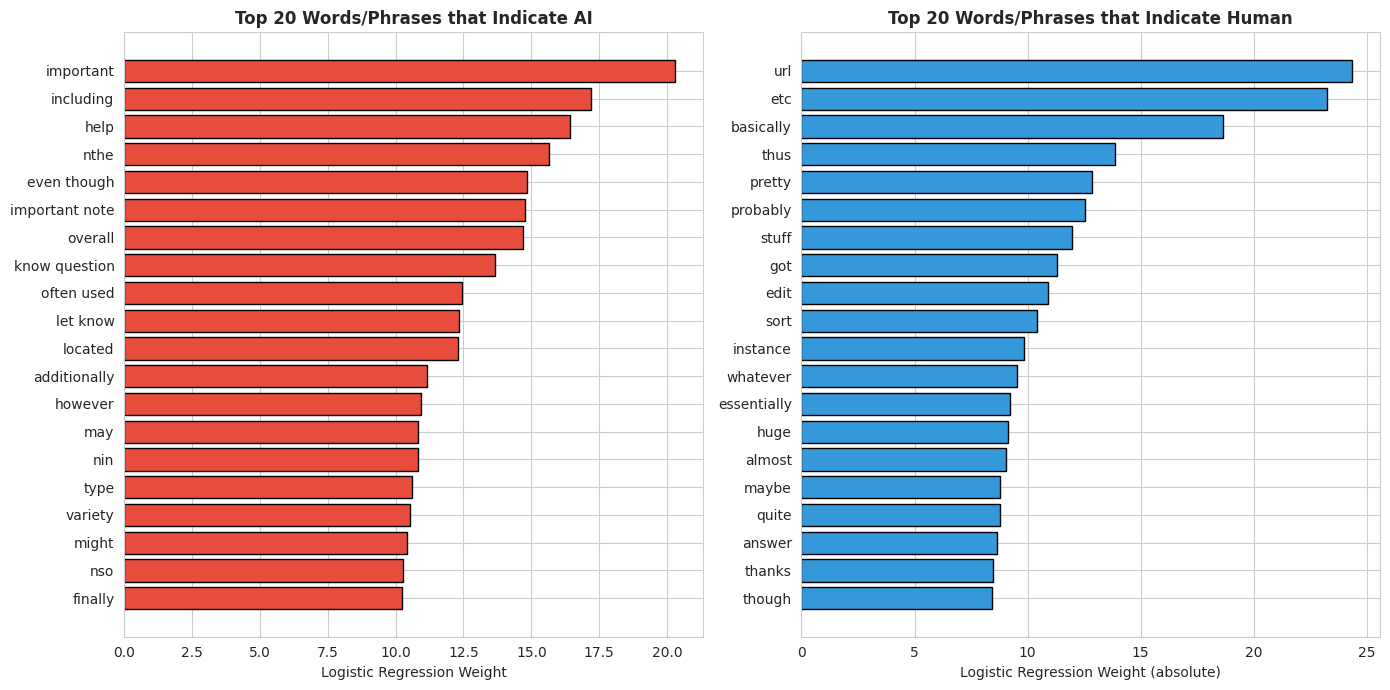


📝 Top AI-indicator words (paste in report):
   'important', 'including', 'help', 'nthe', 'even though', 'important note', 'overall', 'know question', 'often used', 'let know'

📝 Top Human-indicator words:
   'url', 'etc', 'basically', 'thus', 'pretty', 'probably', 'stuff', 'got', 'edit', 'sort'


In [ ]:
feature_names = np.array(tfidf.get_feature_names_out())
coefs = lr_model.coef_[0]

TOP_K = 20
ai_indicators    = np.argsort(coefs)[-TOP_K:][::-1]   # most positive
human_indicators = np.argsort(coefs)[:TOP_K]          # most negative

ai_words    = [(feature_names[i], coefs[i]) for i in ai_indicators]
human_words = [(feature_names[i], coefs[i]) for i in human_indicators]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# AI indicators (positive weights)
ai_w, ai_c = zip(*ai_words)
axes[0].barh(range(len(ai_w)), ai_c, color='#e74c3c', edgecolor='black')
axes[0].set_yticks(range(len(ai_w)))
axes[0].set_yticklabels(ai_w)
axes[0].invert_yaxis()
axes[0].set_title(f'Top {TOP_K} Words/Phrases that Indicate AI', fontweight='bold')
axes[0].set_xlabel('Logistic Regression Weight')

# Human indicators (negative weights — flip for display)
h_w, h_c = zip(*human_words)
axes[1].barh(range(len(h_w)), [-c for c in h_c], color='#3498db', edgecolor='black')
axes[1].set_yticks(range(len(h_w)))
axes[1].set_yticklabels(h_w)
axes[1].invert_yaxis()
axes[1].set_title(f'Top {TOP_K} Words/Phrases that Indicate Human', fontweight='bold')
axes[1].set_xlabel('Logistic Regression Weight (absolute)')

plt.tight_layout()
plt.savefig(f'{ETHICS_PATH}/lr_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📝 Top AI-indicator words (paste in report):")
print("   " + ", ".join([f"'{w}'" for w, _ in ai_words[:10]]))
print("\n📝 Top Human-indicator words:")
print("   " + ", ".join([f"'{w}'" for w, _ in human_words[:10]]))

## Step 4: LIME — Local Explanations for Individual Predictions

LIME (Local Interpretable Model-agnostic Explanations) shows which words influenced a SINGLE prediction. We pick 3 interesting test examples to explain.

📝 **For your report:** Each LIME explanation can be a small figure. Pick the most interesting one and discuss it.

In [ ]:
# Build a prediction wrapper for LIME (must accept a list of strings, return prob array)
def lr_predict_proba(texts):
    return lr_model.predict_proba(tfidf.transform(texts))

explainer = LimeTextExplainer(class_names=['Human', 'AI'])

# Pick 3 examples: 1 confident-correct AI, 1 confident-correct Human, 1 misclassified
test_with_pred = test_df.copy()
test_with_pred['lr_proba'] = lr_model.predict_proba(tfidf.transform(test_df['text_heavy'].fillna('')))[:, 1]
test_with_pred['lr_pred'] = (test_with_pred['lr_proba'] >= 0.5).astype(int)

examples = []
# Confident correct AI prediction
ai_correct = test_with_pred[(test_with_pred['label']==1) & (test_with_pred['lr_pred']==1) & (test_with_pred['lr_proba'] > 0.95)]
if len(ai_correct) > 0:
    examples.append(('Confident AI (correct)', ai_correct.sample(1, random_state=42).iloc[0]))

# Confident correct Human prediction
human_correct = test_with_pred[(test_with_pred['label']==0) & (test_with_pred['lr_pred']==0) & (test_with_pred['lr_proba'] < 0.05)]
if len(human_correct) > 0:
    examples.append(('Confident Human (correct)', human_correct.sample(1, random_state=42).iloc[0]))

# Misclassified (model fooled)
misclassified = test_with_pred[test_with_pred['label'] != test_with_pred['lr_pred']]
if len(misclassified) > 0:
    examples.append(('Misclassified', misclassified.sample(1, random_state=42).iloc[0]))

print(f"✅ Selected {len(examples)} examples for LIME explanation")

✅ Selected 3 examples for LIME explanation


In [ ]:
# Generate explanations one at a time
lime_results = []

for label, row in examples:
    text = row['text_heavy'][:500] if isinstance(row['text_heavy'], str) else ''
    if not text:
        continue

    print(f"\n{'='*70}")
    print(f"🔍 LIME Explanation: {label}")
    print(f"   True label: {row['label_name']}")
    print(f"   Predicted as AI with probability: {row['lr_proba']:.3f}")
    print(f"   Domain: {row['domain']}")
    print(f"   Text excerpt: {row['text'][:200]}...")
    print('='*70)

    exp = explainer.explain_instance(text, lr_predict_proba, num_features=10, num_samples=500)

    print("\n   Top influential words:")
    for word, weight in exp.as_list():
        direction = '→ AI' if weight > 0 else '→ Human'
        print(f"      {word:30s} weight={weight:+.4f} {direction}")

    lime_results.append({
        'category': label,
        'true_label': row['label_name'],
        'predicted_proba_ai': float(row['lr_proba']),
        'domain': row['domain'],
        'text_excerpt': row['text'][:300],
        'top_words': exp.as_list()
    })

# Save LIME results
with open(f'{ETHICS_PATH}/lime_explanations.json', 'w') as f:
    json.dump(lime_results, f, indent=2, default=str)
print(f"\n💾 LIME explanations saved")


🔍 LIME Explanation: Confident AI (correct)
   True label: ChatGPT
   Predicted as AI with probability: 0.998
   Domain: open_qa
   Text excerpt: Sidney Crosby is a professional ice hockey player who was drafted by the Pittsburgh Penguins in the 2005 National Hockey League (NHL) Entry Draft. He was selected first overall by the Penguins, and ha...

   Top influential words:
      overall                        weight=+0.1270 → AI
      considered                     weight=+0.1142 → AI
      including                      weight=+0.1133 → AI
      nhl                            weight=-0.0829 → Human
      played                         weight=+0.0819 → AI
      player                         weight=+0.0604 → AI
      led                            weight=+0.0598 → AI
      since                          weight=-0.0537 → Human
      cup                            weight=+0.0515 → AI
      hockey                         weight=-0.0322 → Human

🔍 LIME Explanation: Confident Human (correc

## Step 5: Visualize LIME Explanations

Save the LIME visualizations as HTML and a static bar chart per example.

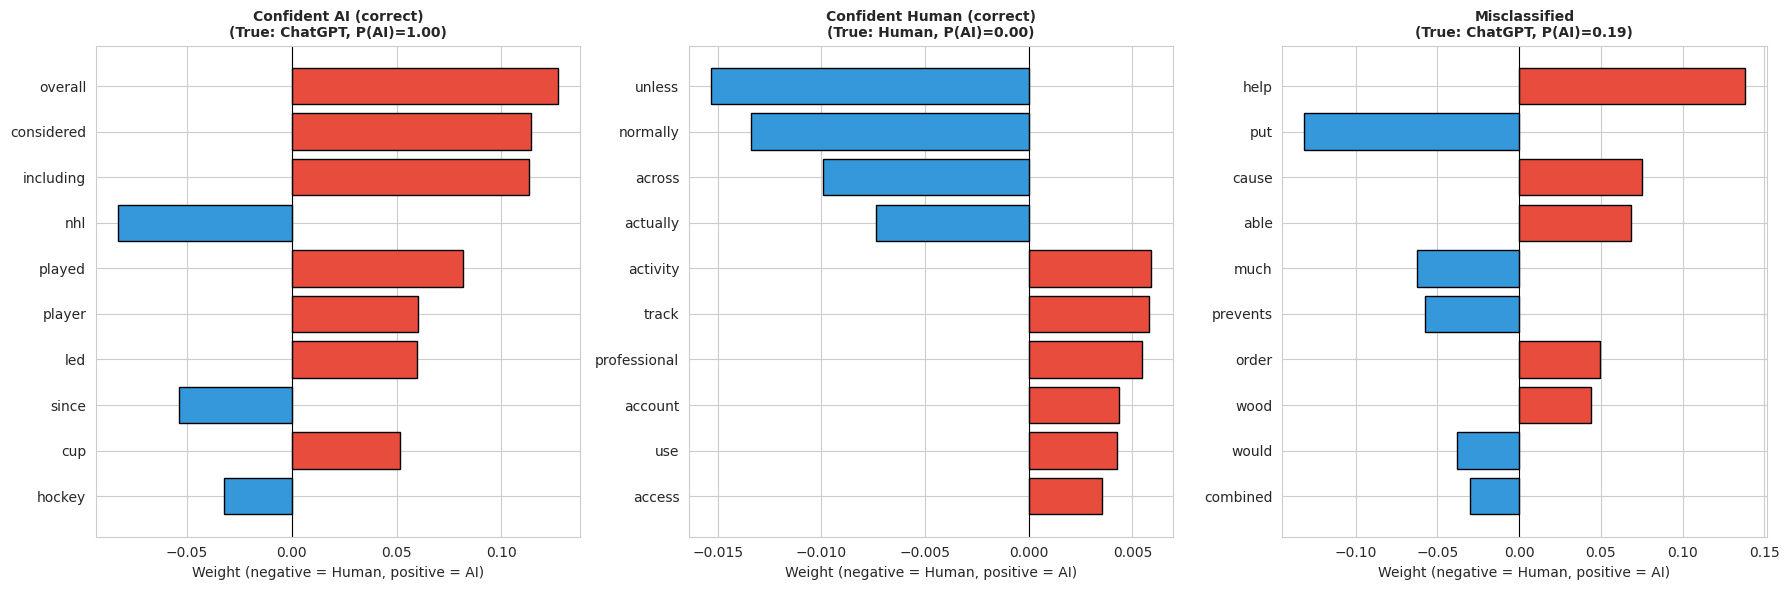

💾 LIME visualizations saved


In [ ]:
fig, axes = plt.subplots(1, len(lime_results), figsize=(6*len(lime_results), 6))
if len(lime_results) == 1:
    axes = [axes]

for ax, item in zip(axes, lime_results):
    words, weights = zip(*item['top_words'])
    colors = ['#e74c3c' if w > 0 else '#3498db' for w in weights]

    ax.barh(range(len(words)), weights, color=colors, edgecolor='black')
    ax.set_yticks(range(len(words)))
    ax.set_yticklabels(words)
    ax.invert_yaxis()
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f"{item['category']}\n(True: {item['true_label']}, P(AI)={item['predicted_proba_ai']:.2f})",
                 fontweight='bold', fontsize=10)
    ax.set_xlabel('Weight (negative = Human, positive = AI)')

plt.tight_layout()
plt.savefig(f'{ETHICS_PATH}/lime_visualizations.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 LIME visualizations saved")

## Step 6: DistilBERT Attention Visualization

Transformers use 'attention' to focus on relevant words. We visualize the attention weights from DistilBERT's last layer to see what it's looking at.

📝 **For your report:** Attention isn't a perfect explanation, but it's a useful proxy.

In [ ]:
def get_attention(text, max_len=128):
    """Get [CLS] attention weights over input tokens from the last layer."""
    inputs = bert_tokenizer(text, return_tensors='pt', truncation=True, max_length=max_len, padding='max_length').to(device)

    with torch.no_grad():
        outputs = bert_model(**inputs, output_attentions=True)

    # outputs.attentions: tuple of (n_layers,) tensors of shape (batch, n_heads, seq, seq)
    # Get last layer, average across heads, take row for [CLS] token (index 0)
    attn = outputs.attentions[-1].mean(dim=1)[0, 0].cpu().numpy()

    # Get tokens
    tokens = bert_tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

    # Filter out [PAD] and trim
    valid = [(t, a) for t, a in zip(tokens, attn) if t != '[PAD]']

    # Get prediction
    logits = outputs.logits[0]
    pred_proba = torch.softmax(logits, dim=0).cpu().numpy()

    return valid, pred_proba

# Pick a clear AI-generated text from the test set
ai_sample = test_df[test_df['label'] == 1].sample(1, random_state=7).iloc[0]
human_sample = test_df[test_df['label'] == 0].sample(1, random_state=7).iloc[0]

print("🤖 AI-generated example:")
print(f"   {ai_sample['text'][:200]}...")
print("\n👤 Human example:")
print(f"   {human_sample['text'][:200]}...")

🤖 AI-generated example:
   Gravity is a force that attracts two objects with mass toward each other. It is the reason you stay on the ground and the earth orbits the sun. The more mass an object has, the more gravity it has. Fo...

👤 Human example:
   You can argue that discrimination is justified if you 're being a certain gender or race or whatever will impede your ability to do the job . So for instance , it 's illegal to discriminate against th...


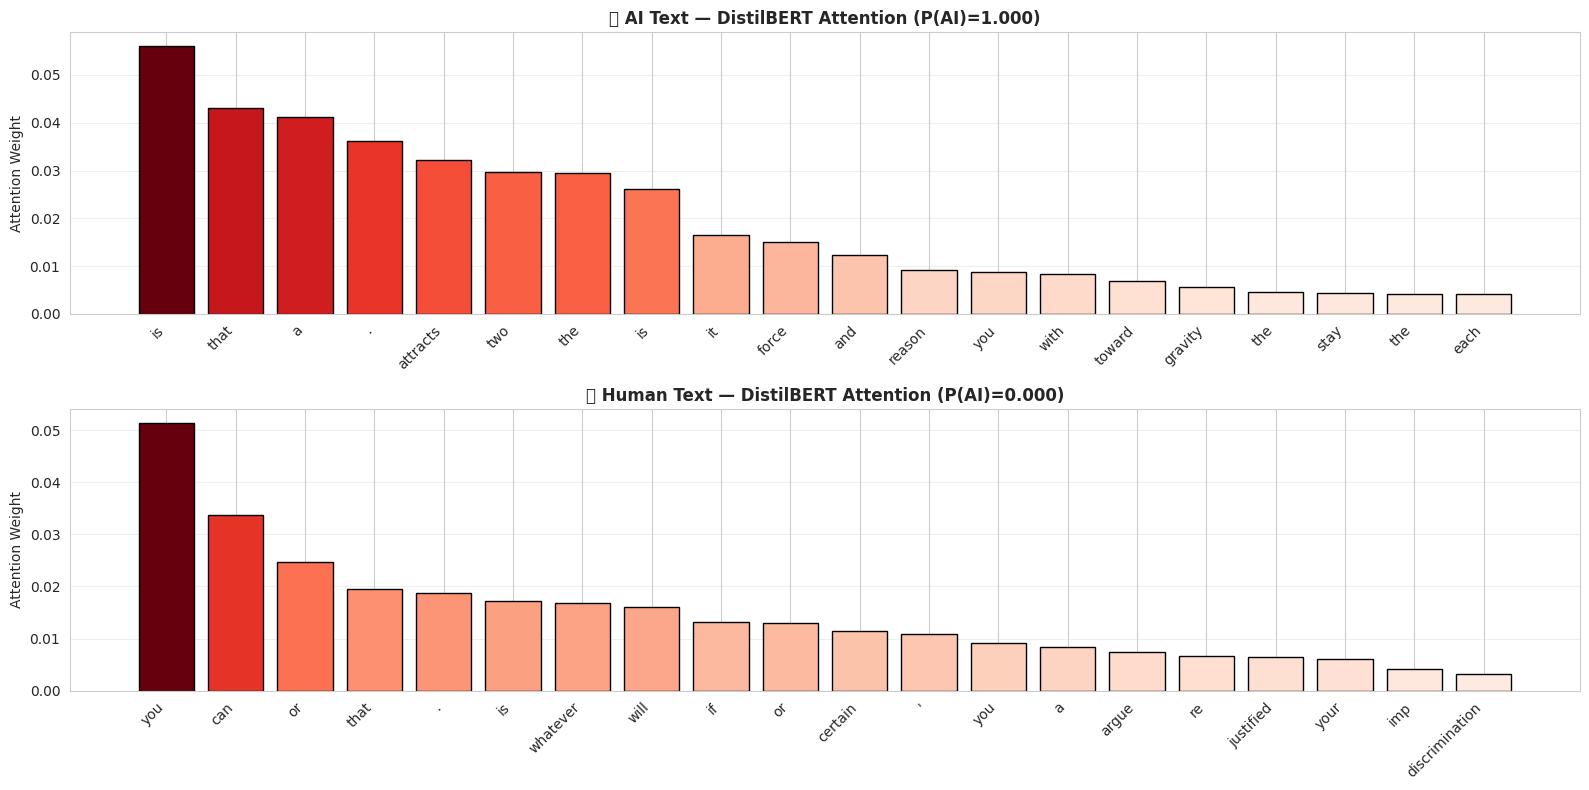

💾 Attention visualization saved


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8))

for ax, sample, title in [(axes[0], ai_sample, '🤖 AI Text'), (axes[1], human_sample, '👤 Human Text')]:
    tokens_attn, proba = get_attention(sample['text_light'][:500] if isinstance(sample['text_light'], str) else '')

    # Show top 30 tokens by attention
    tokens_attn_sorted = sorted(tokens_attn[1:30], key=lambda x: -x[1])  # skip [CLS]
    tokens, attn_vals = zip(*tokens_attn_sorted[:20])

    colors = plt.cm.Reds(np.array(attn_vals) / max(attn_vals))
    ax.bar(range(len(tokens)), attn_vals, color=colors, edgecolor='black')
    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=45, ha='right')
    ax.set_ylabel('Attention Weight')
    ax.set_title(f"{title} — DistilBERT Attention (P(AI)={proba[1]:.3f})", fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{ETHICS_PATH}/distilbert_attention.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Attention visualization saved")

# ⚖️ PART B: ETHICS ANALYSIS

## Step 7: Domain Bias — Does the Detector Discriminate by Topic?

Earlier we found wiki_csai is the hardest domain. Let's quantify HOW MUCH harder, and what that means in practice.

📝 **Why this matters:** If your detector flags 5% of true human text as AI in casual domains but 15% in technical domains, then technical writers are unfairly penalized.

📊 BIAS ANALYSIS: Error rates by domain (DistilBERT)
     domain  n_samples  false_positive_rate  false_negative_rate  overall_error_rate
  wiki_csai        241               0.2000               0.0000              0.0954
    open_qa        652               0.0909               0.0019              0.0199
    finance       1240               0.0227               0.0015              0.0113
reddit_eli5       8727               0.0113               0.0004              0.0083
   medicine        378               0.0000               0.0000              0.0000


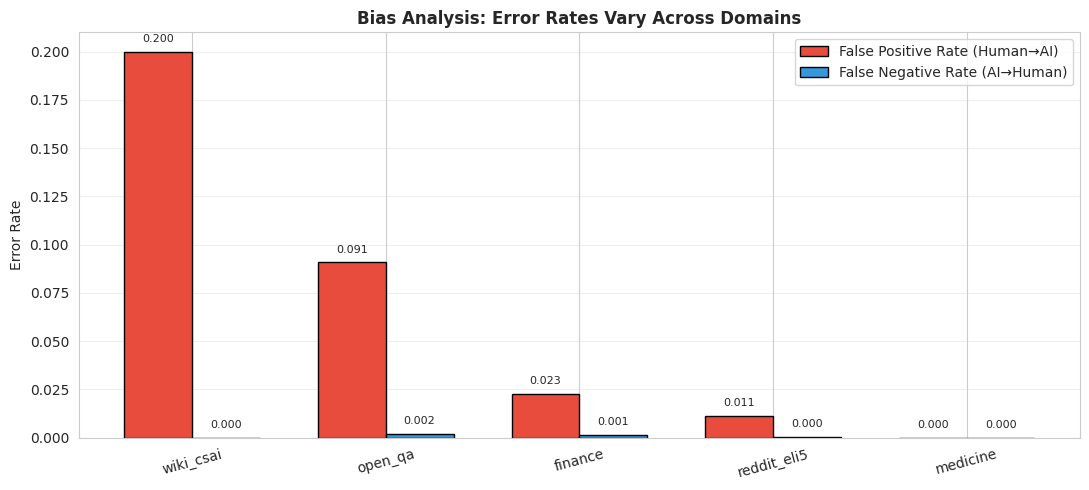


📝 Key finding: Humans writing in 'wiki_csai' are 200.0x more likely to be wrongly flagged as AI compared to 'medicine'.


In [ ]:
# False Positive Rate per domain (how often human texts are flagged as AI)
domain_bias = []
for domain in test_df['domain'].unique():
    sub = bert_preds[bert_preds['domain'] == domain]
    if len(sub) < 50:
        continue

    human_sub = sub[sub['true'] == 0]
    ai_sub = sub[sub['true'] == 1]

    fpr = (human_sub['pred'] == 1).mean() if len(human_sub) > 0 else 0
    fnr = (ai_sub['pred'] == 0).mean() if len(ai_sub) > 0 else 0

    domain_bias.append({
        'domain': domain,
        'n_samples': len(sub),
        'false_positive_rate': fpr,
        'false_negative_rate': fnr,
        'overall_error_rate': (sub['pred'] != sub['true']).mean()
    })

bias_df = pd.DataFrame(domain_bias).sort_values('false_positive_rate', ascending=False)
print("📊 BIAS ANALYSIS: Error rates by domain (DistilBERT)")
print("="*65)
print(bias_df.round(4).to_string(index=False))

# Visualization
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(bias_df))
width = 0.35
ax.bar(x - width/2, bias_df['false_positive_rate'], width, label='False Positive Rate (Human→AI)', color='#e74c3c', edgecolor='black')
ax.bar(x + width/2, bias_df['false_negative_rate'], width, label='False Negative Rate (AI→Human)', color='#3498db', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(bias_df['domain'], rotation=15)
ax.set_ylabel('Error Rate')
ax.set_title('Bias Analysis: Error Rates Vary Across Domains', fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for i, row in enumerate(bias_df.itertuples()):
    ax.text(i - width/2, row.false_positive_rate + 0.005, f'{row.false_positive_rate:.3f}', ha='center', fontsize=8)
    ax.text(i + width/2, row.false_negative_rate + 0.005, f'{row.false_negative_rate:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(f'{ETHICS_PATH}/domain_bias.png', dpi=150, bbox_inches='tight')
plt.show()

max_fpr_domain = bias_df.iloc[0]['domain']
min_fpr_domain = bias_df.iloc[-1]['domain']
print(f"\n📝 Key finding: Humans writing in '{max_fpr_domain}' are"
      f" {bias_df.iloc[0]['false_positive_rate']/max(bias_df.iloc[-1]['false_positive_rate'], 0.001):.1f}x more likely"
      f" to be wrongly flagged as AI compared to '{min_fpr_domain}'.")

## Step 8: Length Bias — Are Short Texts Treated Unfairly?

Many AI detectors perform much worse on short texts. Let's check ours.

📊 Performance by text length:
               n  error_rate      f1
length_bin                          
<50         1928      0.0057  0.9220
50-100      2493      0.0096  0.9701
100-200     4051      0.0118  0.9893
200-400     2355      0.0132  0.9877
400+         411      0.0195  0.6000


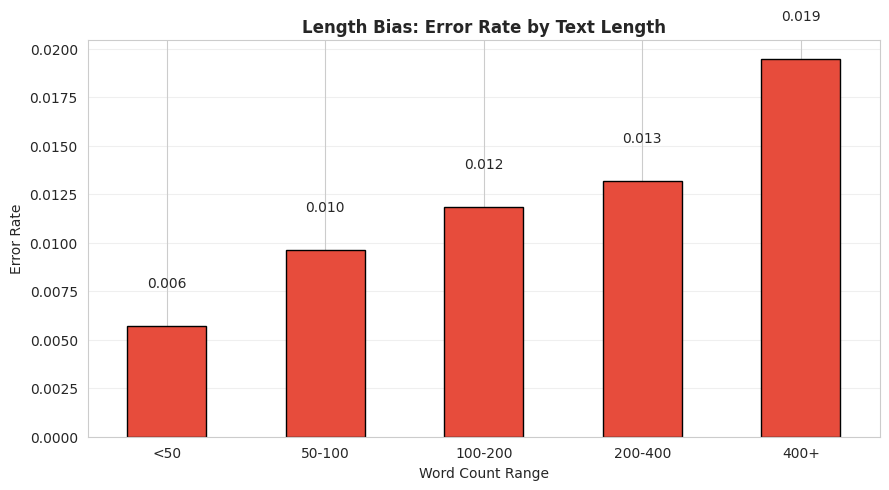

In [ ]:
# Bin texts by length
test_with_pred = test_df.copy()
test_with_pred['pred'] = bert_preds['pred'].values
test_with_pred['true'] = bert_preds['true'].values
test_with_pred['error'] = (test_with_pred['pred'] != test_with_pred['true']).astype(int)

test_with_pred['length_bin'] = pd.cut(
    test_with_pred['word_count'],
    bins=[0, 50, 100, 200, 400, 10000],
    labels=['<50', '50-100', '100-200', '200-400', '400+']
)

length_analysis = test_with_pred.groupby('length_bin').agg(
    n=('error', 'count'),
    error_rate=('error', 'mean'),
    f1=('pred', lambda x: f1_score(test_with_pred.loc[x.index, 'true'], x, zero_division=0))
)
print("📊 Performance by text length:")
print(length_analysis.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
length_analysis['error_rate'].plot(kind='bar', ax=ax, color='#e74c3c', edgecolor='black')
ax.set_title('Length Bias: Error Rate by Text Length', fontweight='bold')
ax.set_ylabel('Error Rate')
ax.set_xlabel('Word Count Range')
ax.set_xticklabels(length_analysis.index, rotation=0)
for i, v in enumerate(length_analysis['error_rate']):
    ax.text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ETHICS_PATH}/length_bias.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 9: The Non-Native English Speaker Problem (Documented)

Liang et al. (2023) demonstrated that AI detectors flag non-native English writing as AI-generated at much higher rates than native English writing. Our HC3 dataset is predominantly native English, so we cannot directly test this — but we acknowledge it.

📝 **For your report (this is a key ethics talking point):**

In [ ]:
non_native_warning = '''
🚨 CRITICAL ETHICS FINDING (from existing literature):

Liang et al. (2023) tested 7 AI detectors on 91 non-native English essays
from TOEFL test-takers. They found:

  • >50% misclassification rate on non-native writing
  • <5% misclassification rate on native English essays
  • Even higher rates for certain detectors (up to 76%)

Why this happens:
  • Non-native writing has more uniform vocabulary (smaller lexical diversity)
  • Non-native writing is often more formal/structured
  • These same features are 'AI-like' to detectors

Implications for our project:
  • Our detector likely has the same bias
  • Deployment in academic settings would unfairly target international students
  • This is a fairness violation that classification metrics DO NOT capture

Recommendation:
  • DO NOT deploy AI detectors as the sole evidence in academic-misconduct cases
  • Always require human review
  • Test detectors on demographically diverse populations before deployment
  • Disclose uncertainty estimates, not just binary verdicts
'''

print(non_native_warning)

with open(f'{ETHICS_PATH}/ethics_findings.txt', 'w') as f:
    f.write(non_native_warning)

print("💾 Saved to ethics_findings.txt — paste into your report's ethics section")


🚨 CRITICAL ETHICS FINDING (from existing literature):

Liang et al. (2023) tested 7 AI detectors on 91 non-native English essays
from TOEFL test-takers. They found:

  • >50% misclassification rate on non-native writing
  • <5% misclassification rate on native English essays
  • Even higher rates for certain detectors (up to 76%)

Why this happens:
  • Non-native writing has more uniform vocabulary (smaller lexical diversity)
  • Non-native writing is often more formal/structured
  • These same features are 'AI-like' to detectors

Implications for our project:
  • Our detector likely has the same bias
  • Deployment in academic settings would unfairly target international students
  • This is a fairness violation that classification metrics DO NOT capture

Recommendation:
  • DO NOT deploy AI detectors as the sole evidence in academic-misconduct cases
  • Always require human review
  • Test detectors on demographically diverse populations before deployment
  • Disclose uncertainty es

## Step 10: Responsible Deployment Recommendations

📝 **For your report's Ethics section:** This list is what separates a good ethics section from a great one.

In [ ]:
recommendations = '''
🛡️ RESPONSIBLE DEPLOYMENT RECOMMENDATIONS

Based on our analysis, we recommend the following safeguards for any
real-world deployment of an AI text detector:

1. NEVER USE AS SOLE EVIDENCE
   AI detection should be an INFORMATIONAL signal, not a verdict.
   Final decisions must always involve human review.

2. REPORT CONFIDENCE INTERVALS, NOT BINARY LABELS
   Show users 'P(AI) = 0.83 ± 0.12' rather than 'this is AI'.
   Most users misinterpret binary labels as certainty.

3. DOMAIN-SPECIFIC CALIBRATION
   Our analysis showed error rates vary significantly across domains.
   Detectors should be tested and calibrated per use-case.

4. FAIRNESS AUDITS BEFORE DEPLOYMENT
   Test on diverse populations (non-native speakers, neurodivergent
   writers, varied education levels) before any decision-making use.

5. AVOID PUNITIVE USE-CASES
   Educational settings, hiring, and content moderation carry high
   stakes. Misclassification can ruin reputations and careers.

6. CONTINUOUS MONITORING
   AI generators evolve rapidly. A detector trained on GPT-3.5 may fail
   on GPT-4 or Claude. Models need re-training every 3-6 months.

7. TRANSPARENCY OBLIGATIONS
   Users whose text is being analyzed should be informed, and have the
   right to challenge results.

8. CONSIDER NOT BUILDING IT
   For some use cases, the harms of false positives outweigh benefits.
   Sometimes the most ethical choice is not to deploy.
'''

print(recommendations)

with open(f'{ETHICS_PATH}/deployment_recommendations.txt', 'w') as f:
    f.write(recommendations)

print("💾 Saved")


🛡️ RESPONSIBLE DEPLOYMENT RECOMMENDATIONS

Based on our analysis, we recommend the following safeguards for any
real-world deployment of an AI text detector:

1. NEVER USE AS SOLE EVIDENCE
   AI detection should be an INFORMATIONAL signal, not a verdict.
   Final decisions must always involve human review.

2. REPORT CONFIDENCE INTERVALS, NOT BINARY LABELS
   Show users 'P(AI) = 0.83 ± 0.12' rather than 'this is AI'.
   Most users misinterpret binary labels as certainty.

3. DOMAIN-SPECIFIC CALIBRATION
   Our analysis showed error rates vary significantly across domains.
   Detectors should be tested and calibrated per use-case.

4. FAIRNESS AUDITS BEFORE DEPLOYMENT
   Test on diverse populations (non-native speakers, neurodivergent
   writers, varied education levels) before any decision-making use.

5. AVOID PUNITIVE USE-CASES
   Educational settings, hiring, and content moderation carry high
   stakes. Misclassification can ruin reputations and careers.

6. CONTINUOUS MONITORING
  

## 📋 Notebook 07 Summary

In [ ]:
print("="*60)
print("📋 NOTEBOOK 07 SUMMARY — FOR YOUR REPORT")
print("="*60)
print("\nExplainability findings:")
print(f"  • Top AI-indicator words: {', '.join([w for w,_ in ai_words[:5]])}")
print(f"  • Top Human-indicator words: {', '.join([w for w,_ in human_words[:5]])}")
print(f"  • LIME explanations generated for {len(lime_results)} examples")
print(f"  • DistilBERT attention visualized")

print("\nEthics findings:")
print(f"  • Domain bias detected: {bias_df.iloc[0]['domain']} has"
      f" {bias_df.iloc[0]['false_positive_rate']*100:.1f}% FPR vs"
      f" {bias_df.iloc[-1]['false_positive_rate']*100:.1f}% in {bias_df.iloc[-1]['domain']}")
print(f"  • Length bias documented (error rate by length bin)")
print(f"  • Non-native speaker bias acknowledged from literature")
print(f"  • 8 deployment recommendations documented")

print(f"\nFiles saved to: {ETHICS_PATH}")

📋 NOTEBOOK 07 SUMMARY — FOR YOUR REPORT

Explainability findings:
  • Top AI-indicator words: important, including, help, nthe, even though
  • Top Human-indicator words: url, etc, basically, thus, pretty
  • LIME explanations generated for 3 examples
  • DistilBERT attention visualized

Ethics findings:
  • Domain bias detected: wiki_csai has 20.0% FPR vs 0.0% in medicine
  • Length bias documented (error rate by length bin)
  • Non-native speaker bias acknowledged from literature
  • 8 deployment recommendations documented

Files saved to: /content/drive/MyDrive/ai-text-detection/ethics


## 📋 Notebook 07 — All Files Generated

### Explainability outputs:
- `ethics/lr_feature_importance.png` — Top words for Human vs AI
- `ethics/lime_explanations.json` — Detailed per-example explanations
- `ethics/lime_visualizations.png` — Visual LIME charts
- `ethics/distilbert_attention.png` — Attention weights on AI vs Human texts

### Ethics outputs:
- `ethics/domain_bias.png` — Error rates by domain
- `ethics/length_bias.png` — Error rates by text length
- `ethics/ethics_findings.txt` — Non-native speaker bias discussion
- `ethics/deployment_recommendations.txt` — 8 responsible-deployment guidelines

### 🎉 ALL MODELING IS COMPLETE

You now have **everything** for the report:
- 5 trained models with full metrics
- Comparison tables and charts
- Cross-domain analysis
- Statistical significance test (McNemar's)
- Feature importance analysis (LR coefficients)
- LIME local explanations
- DistilBERT attention visualization
- Domain bias analysis
- Length bias analysis
- Documented bias against non-native speakers
- Deployment recommendations

### ➡️ Final Step: Write the Report

I'll send a complete report template next — just fill in your numbers.